<center><h1>Do_Mimi_HW6</h1></center>

Name: Mimi Do
<br>
Github Username: mkd222
<br>
USC ID: 8125-6556-10

## 1. Tree-Based Methods

Import packages

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, RocCurveDisplay
from sklearn.pipeline import Pipeline as sklearnPipeline
from sklearn.model_selection import GridSearchCV
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as imblearnPipeline

### (a) Download the APS Failure data

In [3]:
train_set = pd.read_csv("../data/aps_failure_training_set.csv", skiprows = 20, na_values = "na")
test_set = pd.read_csv("../data/aps_failure_test_set.csv", skiprows = 20, na_values = "na")

# Accuracy check
print(train_set.shape)
print(test_set.shape)

(60000, 171)
(16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

-   Arbitrary value technique: replac missing values with a specified arbitrary value
-   Mean/median/mode technique: replace missing values with a statistical average. This is the most popular method
-   Regression analysis technique: replace missing values by using other features in the dataset to predict what those missing values could be
-   Hot deck technique: replace missing values using similar instances from the same dataset
-   Cold deck technique: replace missing values using similar instances from an external source

I will be using the median data imputation method because it works well with large datasets and is less affected by outliers

In [ ]:
X_train = train_set.drop(columns = "class")
X_test = test_set.drop(columns = "class")

y_train = train_set["class"]
y_test = test_set["class"]

di_median = X_train.median()

X_train = X_train.fillna(di_median)
X_test = X_test.fillna(di_median)

#### (ii) Calculate the coefficient of variation

In [6]:
cv = X_train.std() / X_train.mean()
print(cv)

aa_000      2.450938
ab_000     10.383494
ac_000      2.310241
ad_000    244.322816
ae_000     24.200137
             ...    
ee_007      5.012754
ee_008      3.259079
ee_009      5.691612
ef_000     49.366659
eg_000     42.481747
Length: 170, dtype: float64


#### (iii) Plot a correlation matrix

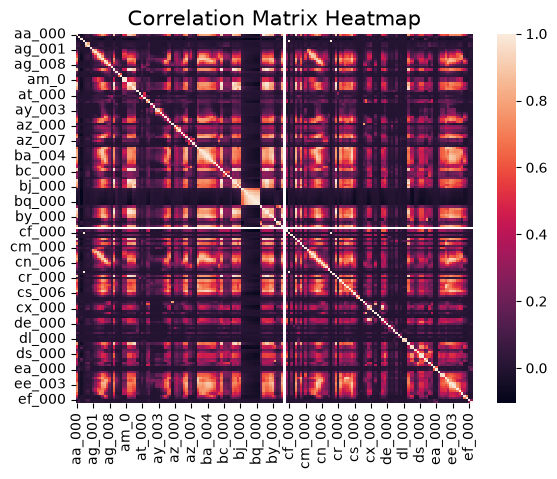

In [12]:
sns.heatmap(X_train.corr())
plt.title("Correlation Matrix Heatmap", fontsize = 15)
plt.show()

#### (iv) Make scatter plots and box plots

In [20]:
high_cv_features = cv.nlargest(13).index
print(high_cv_features)

Index(['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000',
       'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000'],
      dtype='str')


<function matplotlib.pyplot.show(close=None, block=None)>

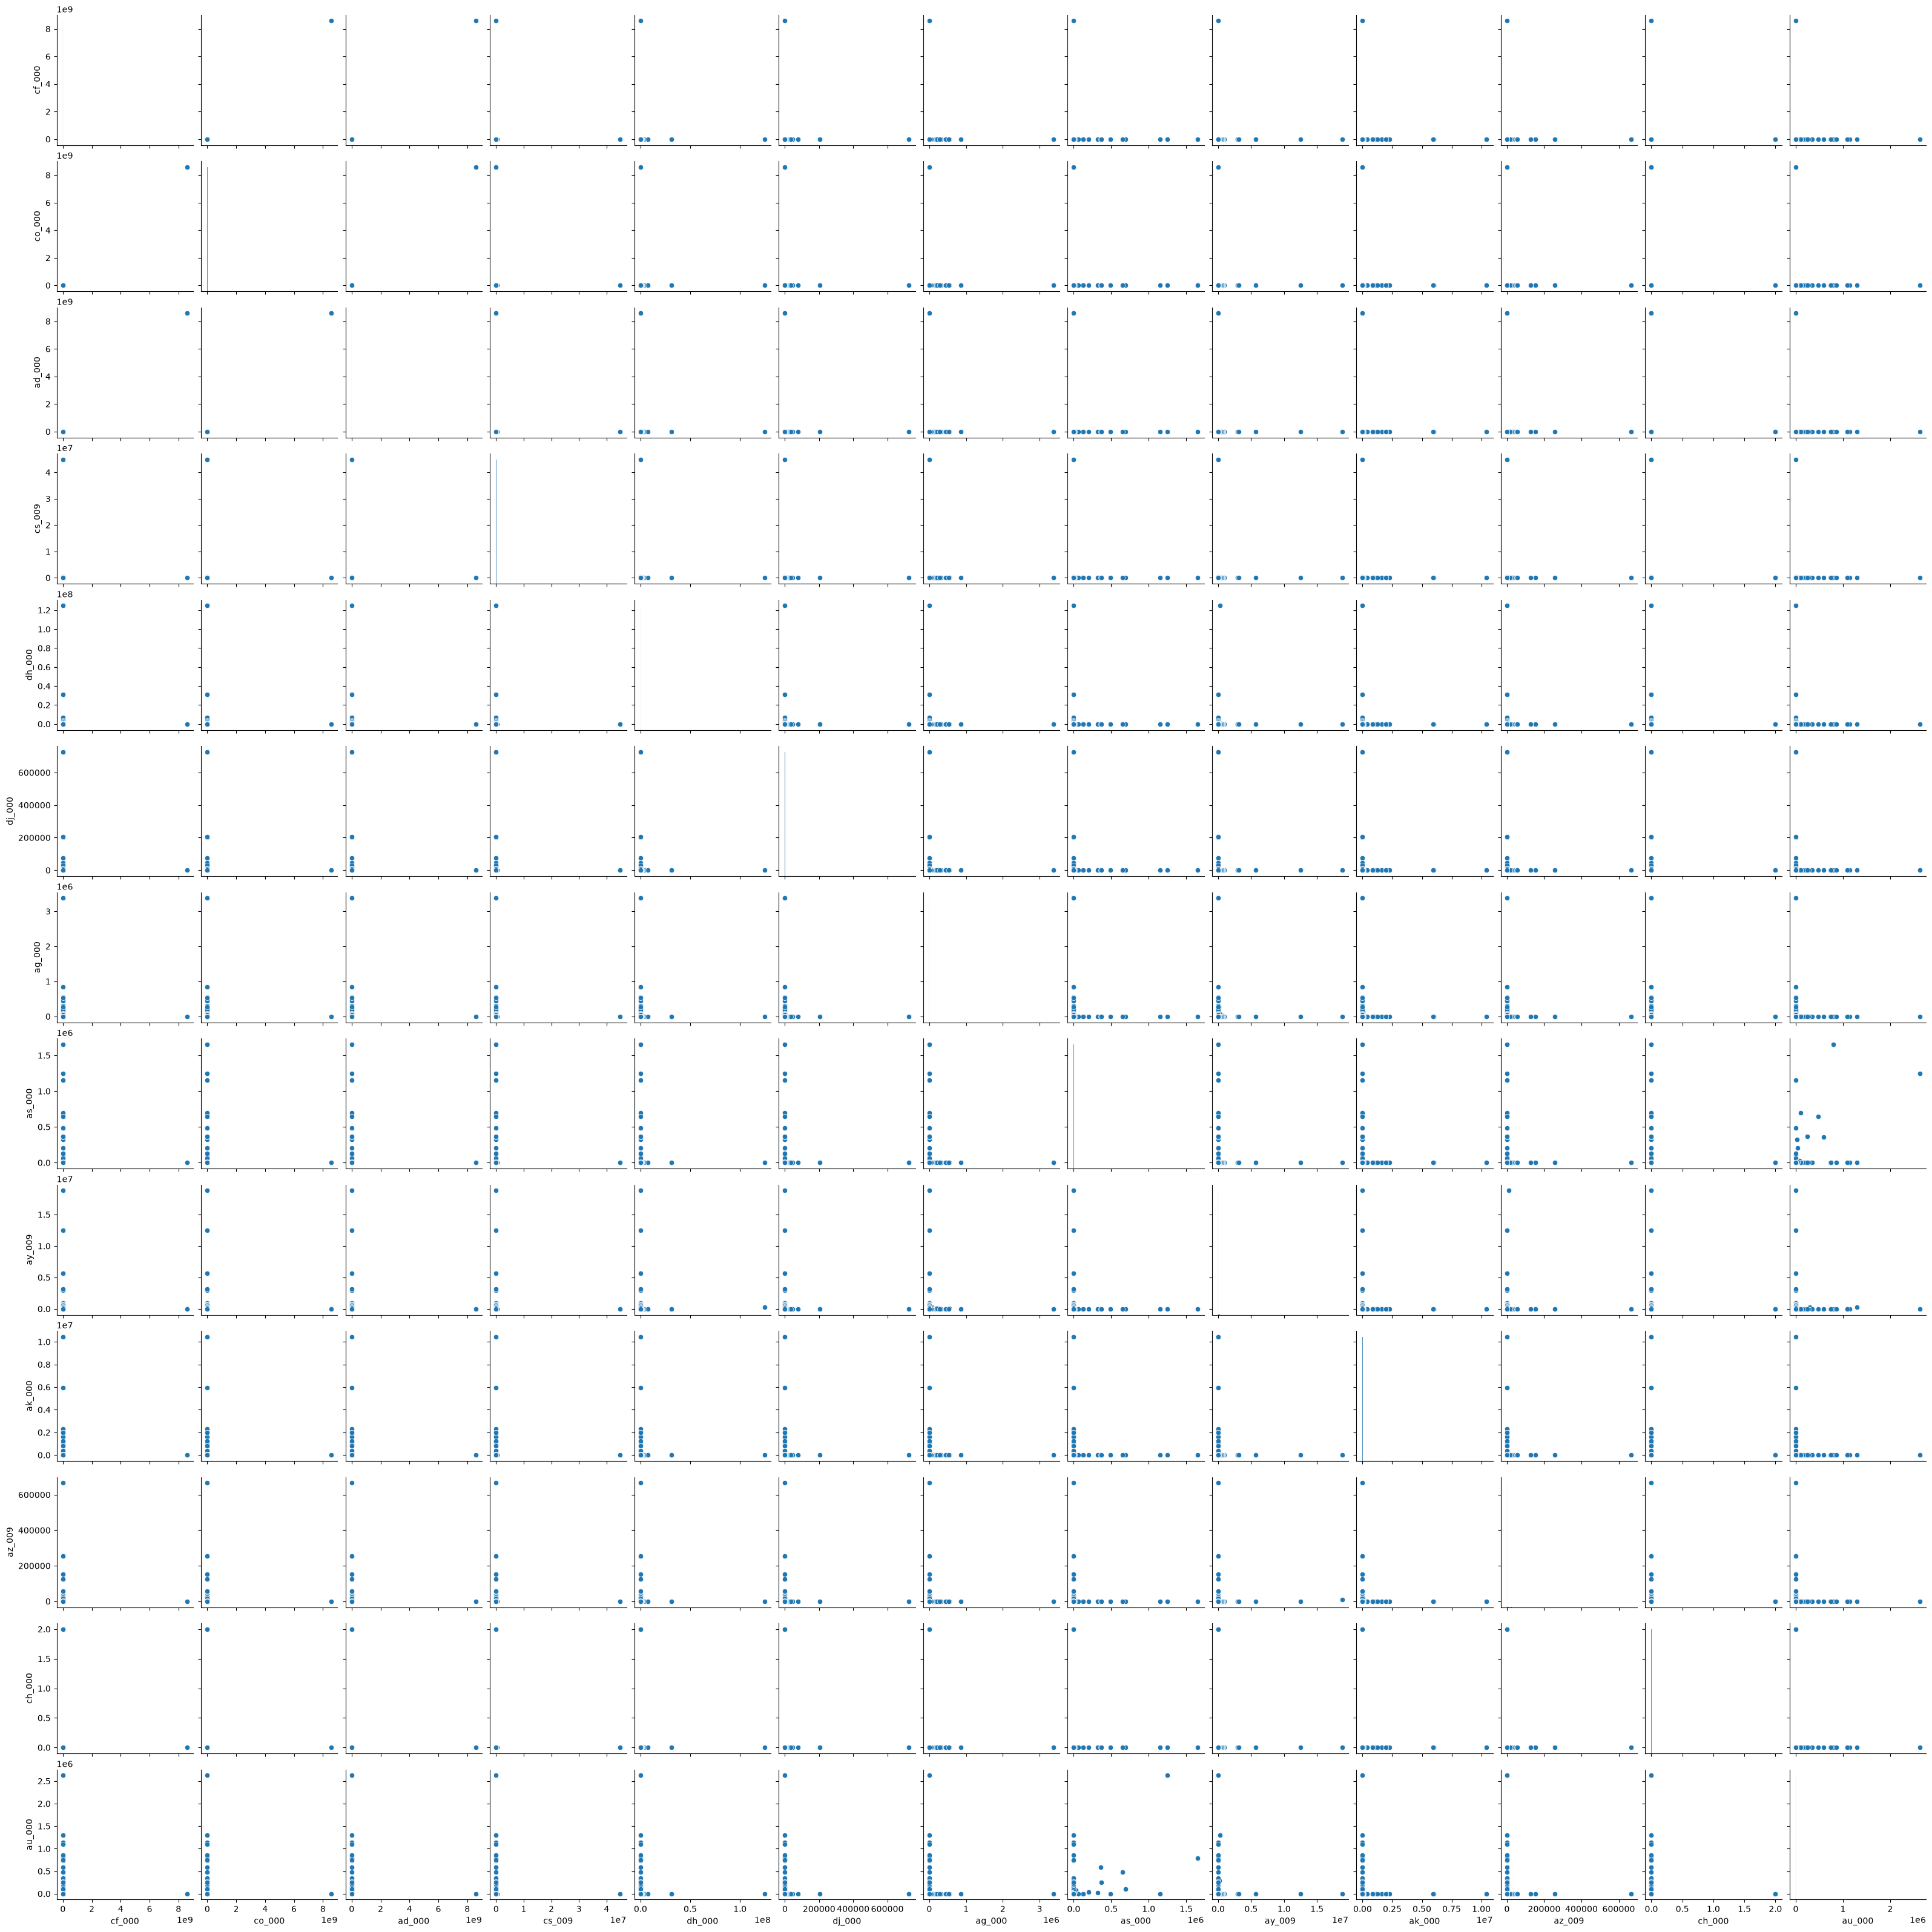

In [ ]:
sns.pairplot(X_train[high_cv_features])
plt.show

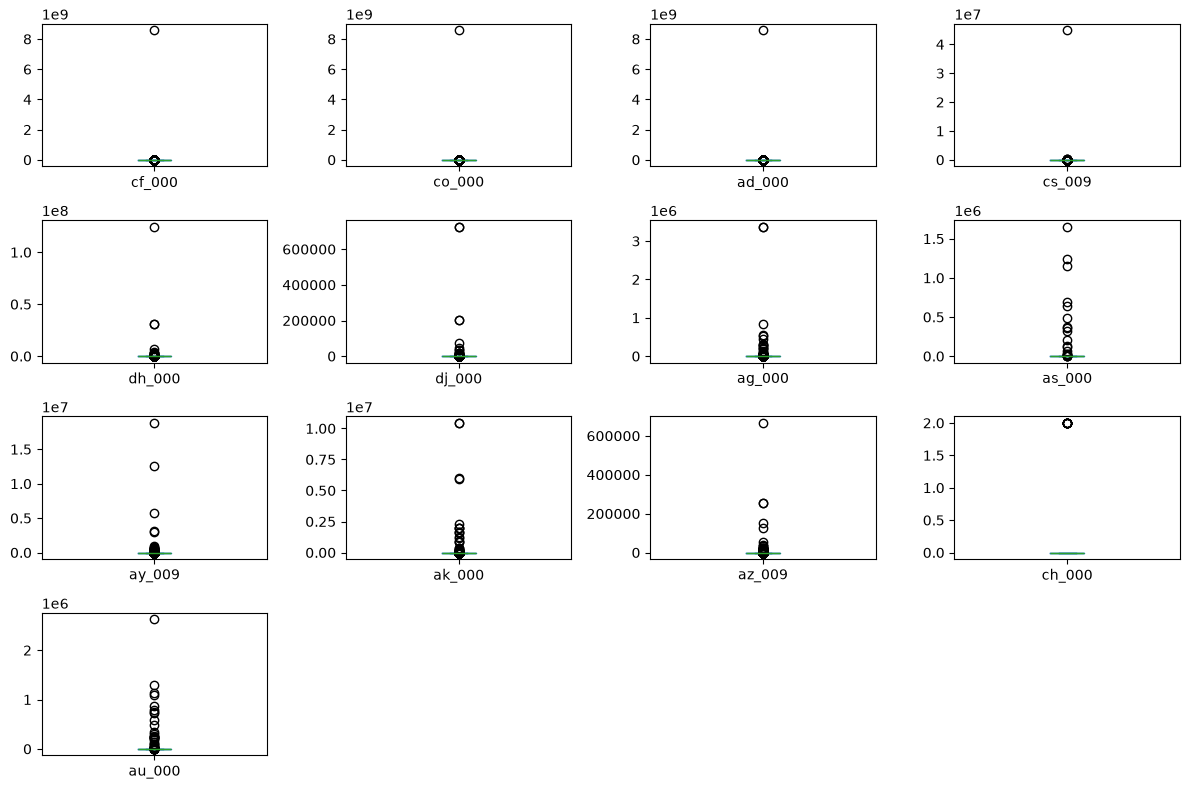

In [36]:
X_train[high_cv_features].plot.box(subplots = True, layout = (4, 4), figsize = (12, 8))
plt.tight_layout()
plt.show()

-   No, we cannot draw conclusions about the significance of the selected features just from looking at the scatterplots because the data points are clustered around zero with some extreme outliers. There are no clear relationships either. We cannot determine statistical significance from just the scatterplots

#### (v) Is this data set imbalanced?

In [37]:
y_train.value_counts()

class
neg    59000
pos     1000
Name: count, dtype: int64

-Yes, this dataset is very imbalanced with 59,000 negative instances and 1,000 positive instances

### (c) Train a random forest

In [44]:
rf = RandomForestClassifier(oob_score = True, random_state = 1)
rf.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the followin

In [74]:
# Confusion matrix
X_train_pred = rf.predict(X_train)
X_test_pred = rf.predict(X_test)

# Train & test error
train_error = 1 - accuracy_score(y_train, X_train_pred)
test_error = 1 - accuracy_score(y_test, X_test_pred)

# OOB error
oob_error = 1 - rf.oob_score_

print("train confusion matrix:")
print(confusion_matrix(y_train, X_train_pred))
print("test confusion matrix:")
print(confusion_matrix(y_test, X_test_pred))
print("train error:", train_error)
print("test error:", round(test_error, 4))
print("OOB error:", round(oob_error, 4))

train confusion matrix:
[[59000     0]
 [    0  1000]]
test confusion matrix:
[[15610    15]
 [  109   266]]
train error: 0.0
test error: 0.0078
OOB error: 0.0061


train AUC:  1.0
test AUC:  0.9944


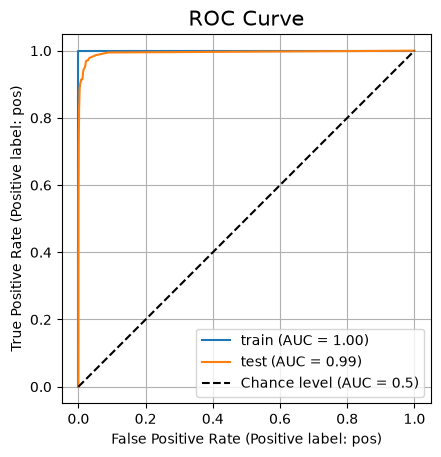

In [65]:
# ROC & AUC
X_train_proba = rf.predict_proba(X_train)[:, 1]
X_test_proba = rf.predict_proba(X_test)[:, 1]

print("train AUC: ", roc_auc_score(y_train, X_train_proba))
print("test AUC: ", round(roc_auc_score(y_test, X_test_proba), 4))

roc_visual = RocCurveDisplay.from_estimator(rf,
                                            X_train,
                                            y_train,
                                            pos_label = "pos",
                                            name = "train").ax_
RocCurveDisplay.from_estimator(rf,
                               X_test,
                               y_test,
                               pos_label = "pos",
                               name = "test",
                               plot_chance_level = True,
                               ax = roc_visual)

plt.title("ROC Curve", fontsize = 15)
plt.grid()
plt.ylim(-0.05, 1.05)
plt.xlim(-0.05, 1.05)
plt.show()

-   OOB error is at 0.0061 while test error is at 0.0078, which makes OOB have a lower error rate than test. They both have very similar error values. Taking into account the confusion matrix and no compensation for class imbalance, the model performs well overall but it could improve the ability to correctly identify the positive class

### (d) Research class imbalance in random forest

-   Weighted random forest: assign more weight to the underrepresented class
-   Resampling (oversampling/undersampling): increase the number of positive instances (SMOTE) or decrease the number of negative instances

I will be using `"balanced_subsample"` to address class imbalance. Initially, I tried using `"balance"`, but the output produced a warning that some instances don't have OOB scores. So then, I tested `class_weight = "balanced_subsample"` which fixed the warning


In [80]:
rf_class_weight = RandomForestClassifier(class_weight = "balanced_subsample", oob_score = True, random_state = 1)
rf_class_weight.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or fl

In [81]:
# Confusion matrix
X_train_pred_cw = rf_class_weight.predict(X_train)
X_test_pred_cw = rf_class_weight.predict(X_test)

# Train & test error
train_error_cw = 1 - accuracy_score(y_train, X_train_pred_cw)
test_error_cw = 1 - accuracy_score(y_test, X_test_pred_cw)

# OOB error
oob_error_cw = 1 - rf_class_weight.oob_score_

print("train confusion matrix:")
print(confusion_matrix(y_train, X_train_pred_cw))
print("test confusion matrix:")
print(confusion_matrix(y_test, X_test_pred_cw))
print("train error:", train_error_cw)
print("test error:", round(test_error_cw, 4))
print("OOB error:", round(oob_error_cw, 4))

train confusion matrix:
[[59000     0]
 [    0  1000]]
test confusion matrix:
[[15612    13]
 [  153   222]]
train error: 0.0
test error: 0.0104
OOB error: 0.0079


train AUC:  1.0
test AUC:  0.9909


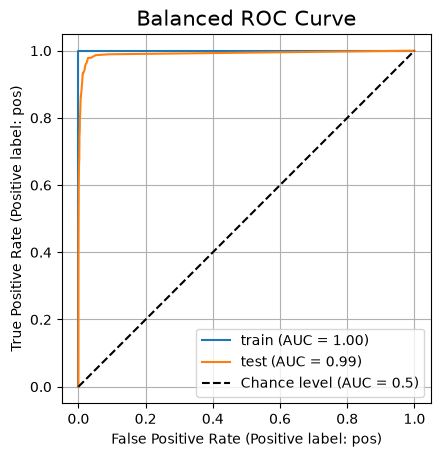

In [82]:
# ROC & AUC
X_train_proba_cw = rf_class_weight.predict_proba(X_train)[:, 1]
X_test_proba_cw = rf_class_weight.predict_proba(X_test)[:, 1]

print("train AUC: ", roc_auc_score(y_train, X_train_proba_cw))
print("test AUC: ", round(roc_auc_score(y_test, X_test_proba_cw), 4))

roc_visual = RocCurveDisplay.from_estimator(rf_class_weight,
                                            X_train,
                                            y_train,
                                            pos_label = "pos",
                                            name = "train").ax_
RocCurveDisplay.from_estimator(rf_class_weight,
                               X_test,
                               y_test,
                               pos_label = "pos",
                               name = "test",
                               plot_chance_level = True,
                               ax = roc_visual)

plt.title("Balanced ROC Curve", fontsize = 15)
plt.grid()
plt.ylim(-0.05, 1.05)
plt.xlim(-0.05, 1.05)
plt.show()

-   After compensating for class imbalance, test error increased from 0.0078 to 0.0104. OOB error is at 0.0079, which still remains similar to the balanced test error. The balanced model missed 44 more APS failaures than the imbalanced model, suggesting that in this context, class weighting does not improve performance

### (e) XGBoost and Model Trees

In [ ]:
X_train_xgb = train_set.drop(columns = "class")
X_test_xgb = test_set.drop(columns = "class")

y_train_xgb = y_train.map({"neg": 0, "pos": 1})
y_test_xgb = y_test.map({"neg": 0, "pos": 1})

xgb_pipe = sklearnPipeline([
    ("median imputation", SimpleImputer(strategy = "median")),
    ("xgb", XGBClassifier(reg_lamda = 0, random_state = 1))])

# Find best alpha
search_a = GridSearchCV(
    xgb_pipe,
    {"xgb__reg_alpha": [0.01, 0.1, 1, 10]},             # default cv = 5
    scoring = "accuracy")

search_a.fit(X_train_xgb, y_train_xgb)

xgb = search_a.best_estimator_              # Saves model with best alpha

print("best alpha:", search_a.best_params_["xgb__reg_alpha"])

best alpha: 0.1


In [105]:
# Confusion matrix
X_train_pred_xgb = xgb.predict(X_train_xgb)
X_test_pred_xgb = xgb.predict(X_test_xgb)

# Train, test, cross-validation errors
train_error_xgb = 1 - accuracy_score(y_train_xgb, X_train_pred_xgb)
test_error_xgb = 1 - accuracy_score(y_test_xgb, X_test_pred_xgb)
cv_error_xgb = 1 - search_a.best_score_

print("train confusion matrix:")
print(confusion_matrix(y_train_xgb, X_train_pred_xgb))
print("test confusion matrix:")
print(confusion_matrix(y_test_xgb, X_test_pred_xgb))
print("train error:",train_error_xgb)
print("test error:", round(test_error_xgb, 4))
print("cross-validation error:", round(cv_error_xgb, 4))

train confusion matrix:
[[59000     0]
 [    1   999]]
test confusion matrix:
[[15606    19]
 [   84   291]]
train error: 1.666666666666483e-05
test error: 0.0064
cross-validation error: 0.0061


train AUC:  0.9999988474576271
test AUC:  0.9937


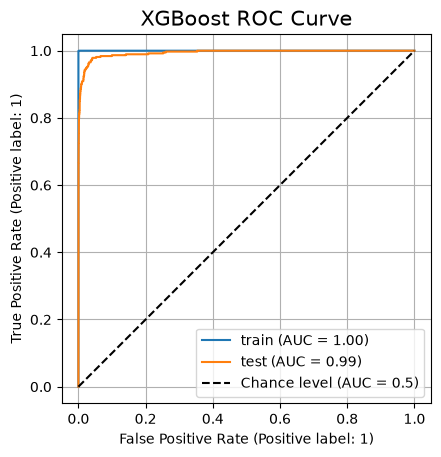

In [103]:
# ROC & AUC
X_train_proba_xgb = xgb.predict_proba(X_train_xgb)[:, 1]
X_test_proba_xgb = xgb.predict_proba(X_test_xgb)[:, 1]

print("train AUC: ", roc_auc_score(y_train_xgb, X_train_proba_xgb))
print("test AUC: ", round(roc_auc_score(y_test_xgb, X_test_proba_xgb), 4))

roc_visual = RocCurveDisplay.from_estimator(xgb,
                                            X_train_xgb,
                                            y_train_xgb,
                                            name = "train").ax_
RocCurveDisplay.from_estimator(xgb,
                               X_test_xgb,
                               y_test_xgb,
                               name = "test",
                               plot_chance_level = True,
                               ax = roc_visual)

plt.title("XGBoost ROC Curve", fontsize = 15)
plt.grid()
plt.ylim(-0.05, 1.05)
plt.xlim(-0.05, 1.05)
plt.show()

-   Cross-validation error is at 0.0061 while test error is at 0.0064. Cross-validation error is slightly lower than test but they are still very similar. Low test error suggests that the XGBoost model generally predicts correctly

### (f) Use SMOTE to pre-process your data

In [112]:
smote_pipe = imblearnPipeline([
    ("median imputation", SimpleImputer(strategy = "median")),
    ("smote", SMOTE(random_state = 1)),
    ("xgb", XGBClassifier(reg_lambda = 0, random_state = 1))])

# Find best alpha 
search_a_smote = GridSearchCV(
    smote_pipe,
    {"xgb__reg_alpha": [0.01, 0.1, 1, 10]},
    scoring = "accuracy")

search_a_smote.fit(X_train_xgb, y_train_xgb)

smote = search_a_smote.best_estimator_              

print("best alpha:", search_a_smote.best_params_["xgb__reg_alpha"])

best alpha: 0.01


In [109]:
# Confusion matrix
X_train_pred_smote = smote.predict(X_train_xgb)
X_test_pred_smote = smote.predict(X_test_xgb)

# Train, test, cross-validation errors
train_error_smote = 1 - accuracy_score(y_train_xgb, X_train_pred_smote)
test_error_smote = 1 - accuracy_score(y_test_xgb, X_test_pred_smote)
cv_error_smote = 1 - search_a_smote.best_score_

print("train confusion matrix:")
print(confusion_matrix(y_train_xgb, X_train_pred_smote))
print("test confusion matrix:")
print(confusion_matrix(y_test_xgb, X_test_pred_smote))
print("train error:",train_error_smote)
print("test error:", round(test_error_smote, 4))
print("cross-validation error:", round(cv_error_smote, 4))

train confusion matrix:
[[59000     0]
 [    1   999]]
test confusion matrix:
[[15580    45]
 [   68   307]]
train error: 1.666666666666483e-05
test error: 0.0071
cross-validation error: 0.0065


train AUC:  0.999999313559322
test AUC:  0.9928


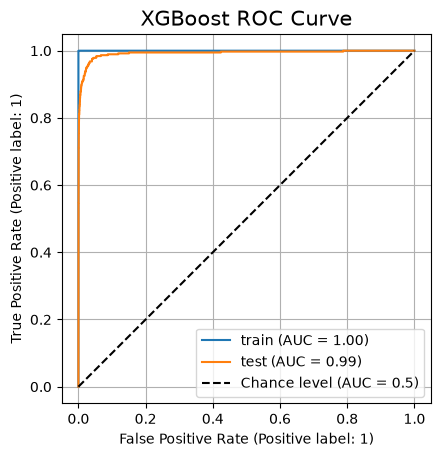

In [110]:
# ROC & AUC
X_train_proba_smote = smote.predict_proba(X_train_xgb)[:, 1]
X_test_proba_smote = smote.predict_proba(X_test_xgb)[:, 1]

print("train AUC: ", roc_auc_score(y_train_xgb, X_train_proba_smote))
print("test AUC: ", round(roc_auc_score(y_test_xgb, X_test_proba_smote), 4))

roc_visual = RocCurveDisplay.from_estimator(smote,
                                            X_train_xgb,
                                            y_train_xgb,
                                            name = "train").ax_
RocCurveDisplay.from_estimator(smote,
                               X_test_xgb,
                               y_test_xgb,
                               name = "test",
                               plot_chance_level = True,
                               ax = roc_visual)

plt.title("XGBoost ROC Curve", fontsize = 15)
plt.grid()
plt.ylim(-0.05, 1.05)
plt.xlim(-0.05, 1.05)
plt.show()

-   SMOTE test error is at 0.0071 while uncompensated test error is at 0.0064, so there is an increase in error after using SMOTE. SMOTE test AUC (0.9928) slightly decreased from uncompensated AUC(0.9937). Additionally,there is a decrease in false negatives from 84 to 68, suggesting that using SMOTE improved the model's ability to correctly identify positives

## 2. ISLR 6.6.3

-   **(a)** iv. Steadily decrease: coefficients can become larger, giving the model more flexibility to better fit the training data
-   **(b)** ii. Decrease initially, and then eventually start increasing in a U shape: The model becomes more flexible but if $s$ is too large, it may overfit the data, leading to test RSS to increase
-   **(c)** iii. Steadily increase: more flexible models tend to be sensitive to changes, which can result in a higher variance
-   **(d)** iv. Steadily decrease: more flexible models can better identify relationships, which reduces underfitting and decreases squared bias
-   **(e)** v. Remain constant: changing $s$ does not affect irreducible error, instead it is affected by random noise in the data 

## 3. ISLR 6.6.5

**(a)**
$$\min_{\beta} \left\{ \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 \right\} \, \text{subject to} \, \sum_{j=1}^{p} \beta_j^2 \leq s$$
Simplified answer: 
$$\min_{\beta_1,\beta_2} \left\{ (y_1 - (\beta_1 + \beta_2)x_{11})^2 + (y_2 - (\beta_1 + \beta_2)x_{21})^2 \right\} \, \text{subject to} \, \beta_1^2 + \beta_2^2 \leq s$$
**(b)** Since both features are identical, their coefficient values contribute equally to model prediction. However, ridge tends to perfer similar coefficients because it minimizes the sum of squared coefficients
<br>
**(c)**
$$\min_{\beta} \left\{ \sum_{i=1}^{n} \left( y_i - \beta_0 - \sum_{j=1}^{p} \beta_j x_{ij} \right)^2 \right\} \, \text{subject to} \, \sum_{j=1}^{p} \left|\beta_j\right| \leq s$$
Simplified answer:
$$\min_{\beta_1,\beta_2} \left\{ (y_1 - (\beta_1 + \beta_2)x_{11})^2 + (y_2 - (\beta_1 + \beta_2)x_{21})^2 \right\} \, \text{subject to} \, |\beta_1| + |\beta_2| \leq s$$
**(d)** Since both features are identical, model prediction depends on the sum of the coefficients. However, lasso does not tend to favor equal coefficients, so multiple combinations can have the same RSS, leading to not unique solutions


## 4. ISLR 8.4.5

$$P(\text{Red} \mid X = 0.5), \quad prob > 0.5 = Red$$
**Majority Vote**
<br>
Vote Red: 6, Vote Green: 4
<br>
Final classification: Red
<br>
**Average Probability**
$$\frac{0.1+ 0.15 + 0.2 + 0.2 + 0.55 + 0.6 + 0.6 + 0.65 + 0.7 + 0.75}{10} = 0.45$$
Final classification: Green


## 5. ISLR 9.7.3

**I attached a pdf file in this notebook folder titled ISLR_9.7.3 that has my handwritten solutions to this question**

### References
-   https://mostly.ai/blog/smart-imputation-with-synthetic-data
-   https://www.publichealth.columbia.edu/research/population-health-methods/missing-data-and-multiple-imputation
-   https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
-   https://medium.com/sfu-cspmp/surviving-in-a-random-forest-with-imbalanced-datasets-b98b963d52eb
-   https://xgboost.readthedocs.io/en/latest/python/python_api.html
-   https://glemaitre.github.io/imbalanced-learn/generated/imblearn.pipeline.Pipeline.html